<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/14_Learning_To_Write_Like_Shakespeare_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 14 — Learning to Write Like Shakespeare: Long Short-Term Memory

**Grokking Deep Learning** (Andrew W. Trask) — Tugas 2: *Code Reproduction + Theoretical Deep-Dive*

Bab 12–13 membangun RNN dan framework. Bab ini memakai keduanya untuk tugas yang lebih sulit: **model bahasa tingkat karakter** yang menghasilkan teks bergaya Shakespeare, memahami mengapa RNN biasa kesulitan (*vanishing/exploding gradient*), dan menggantinya dengan **LSTM**.

**Isi notebook:**
1. Framework dari Bab 13 (disertakan ulang agar notebook mandiri)
2. Data teks dan pemodelan karakter; *batching* dan **truncated backpropagation**
3. Melatih model bahasa karakter dengan `RNNCell`; menghasilkan sampel teks
4. *Vanishing* dan *exploding gradient* (demo buku: sigmoid vs ReLU)
5. LSTM: *forget/input/output gate* dan *cell state* (+ ilustrasi memori)
6. `LSTMCell` dari nol dan pelatihan model bahasa karakter LSTM
7. Perbandingan RNN vs LSTM, tanya-jawab konsep, latihan, rangkuman

> **Catatan data:** buku memakai korpus Shakespeare yang besar (`shakespeare.txt`). `load_text()` mencoba mengunduhnya (memakai bagian awalnya saja agar cepat) dan, bila gagal, memakai **kutipan domain publik** (Sonnet 18 dan soliloqui *Hamlet*) yang tertanam di notebook. Dengan korpus sekecil itu model cenderung **menghafal**; tujuannya adalah memperlihatkan mekanisme, bukan kualitas tulisan. Sumber aktual dicetak pada output.

## 1. Framework (dari Bab 13)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Tensor(object):
    def __init__(self, data, autograd=False, creators=None, creation_op=None, id=None):
        self.data = np.array(data)
        self.autograd = autograd
        self.grad = None
        self.id = np.random.randint(0, 10**9) if id is None else id
        self.creators = creators
        self.creation_op = creation_op
        self.children = {}
        if creators is not None:
            for c in creators:
                c.children[self.id] = c.children.get(self.id, 0) + 1

    def all_children_grads_accounted_for(self):
        return all(cnt == 0 for cnt in self.children.values())

    def backward(self, grad=None, grad_origin=None):
        if not self.autograd: return
        if grad is None: grad = Tensor(np.ones_like(self.data))
        if grad_origin is not None:
            if self.children[grad_origin.id] == 0:
                raise Exception("cannot backprop more than once")
            self.children[grad_origin.id] -= 1
        self.grad = grad if self.grad is None else Tensor(self.grad.data + grad.data)
        assert grad.autograd == False
        if self.creators is not None and (self.all_children_grads_accounted_for() or grad_origin is None):
            op = self.creation_op; c = self.creators
            if op == "add":
                c[0].backward(self.grad, self); c[1].backward(self.grad, self)
            elif op == "sub":
                c[0].backward(Tensor(self.grad.data), self); c[1].backward(Tensor((-self.grad).data), self)
            elif op == "mul":
                c[0].backward(self.grad * c[1], self); c[1].backward(self.grad * c[0], self)
            elif op == "neg":
                c[0].backward((-self.grad), self)
            elif op == "mm":
                c[0].backward(self.grad.mm(c[1].transpose()), self)
                c[1].backward(self.grad.transpose().mm(c[0]).transpose(), self)
            elif op == "transpose":
                c[0].backward(self.grad.transpose(), self)
            elif op.startswith("sum_"):
                dim = int(op.split("_")[1]); c[0].backward(self.grad.expand(dim, c[0].data.shape[dim]), self)
            elif op.startswith("expand_"):
                dim = int(op.split("_")[1]); c[0].backward(self.grad.sum(dim), self)
            elif op == "sigmoid":
                ones = Tensor(np.ones_like(self.grad.data)); c[0].backward(self.grad * (self * (ones - self)), self)
            elif op == "tanh":
                ones = Tensor(np.ones_like(self.grad.data)); c[0].backward(self.grad * (ones - (self * self)), self)
            elif op == "index_select":
                new_grad = np.zeros_like(c[0].data)
                idx = self.index_select_indices.data.flatten()
                g = self.grad.data.reshape(len(idx), -1)
                for i in range(len(idx)): new_grad[idx[i]] += g[i]
                c[0].backward(Tensor(new_grad), self)
            elif op == "cross_entropy":
                dx = (self.softmax_output - self.target_dist) / len(self.target_dist)   # rata-rata atas batch (buku: tanpa pembagian)
                c[0].backward(Tensor(dx), self)

    def _bin(self, other, op, fn):
        if self.autograd and other.autograd:
            return Tensor(fn(self.data, other.data), autograd=True, creators=[self, other], creation_op=op)
        return Tensor(fn(self.data, other.data))
    def __add__(self, other): return self._bin(other, "add", lambda a, b: a + b)
    def __sub__(self, other): return self._bin(other, "sub", lambda a, b: a - b)
    def __mul__(self, other): return self._bin(other, "mul", lambda a, b: a * b)
    def mm(self, x):          return self._bin(x, "mm", lambda a, b: a.dot(b))
    def __neg__(self):
        if self.autograd: return Tensor(self.data * -1, autograd=True, creators=[self], creation_op="neg")
        return Tensor(self.data * -1)
    def sum(self, dim):
        if self.autograd: return Tensor(self.data.sum(dim), autograd=True, creators=[self], creation_op="sum_" + str(dim))
        return Tensor(self.data.sum(dim))
    def expand(self, dim, copies):
        trans_cmd = list(range(0, len(self.data.shape))); trans_cmd.insert(dim, len(self.data.shape))
        new_data = self.data.repeat(copies).reshape(list(self.data.shape) + [copies]).transpose(trans_cmd)
        if self.autograd: return Tensor(new_data, autograd=True, creators=[self], creation_op="expand_" + str(dim))
        return Tensor(new_data)
    def transpose(self):
        if self.autograd: return Tensor(self.data.transpose(), autograd=True, creators=[self], creation_op="transpose")
        return Tensor(self.data.transpose())
    def sigmoid(self):
        if self.autograd: return Tensor(1 / (1 + np.exp(-self.data)), autograd=True, creators=[self], creation_op="sigmoid")
        return Tensor(1 / (1 + np.exp(-self.data)))
    def tanh(self):
        if self.autograd: return Tensor(np.tanh(self.data), autograd=True, creators=[self], creation_op="tanh")
        return Tensor(np.tanh(self.data))
    def index_select(self, indices):
        if self.autograd:
            new = Tensor(self.data[indices.data], autograd=True, creators=[self], creation_op="index_select")
            new.index_select_indices = indices
            return new
        return Tensor(self.data[indices.data])
    def cross_entropy(self, target_indices):
        temp = np.exp(self.data - self.data.max(axis=-1, keepdims=True))
        softmax_output = temp / np.sum(temp, axis=len(self.data.shape) - 1, keepdims=True)
        t = target_indices.data.flatten()
        p = softmax_output.reshape(len(t), -1)
        target_dist = np.eye(p.shape[1])[t]
        loss = -(np.log(p) * target_dist).sum(1).mean()
        if self.autograd:
            out = Tensor(loss, autograd=True, creators=[self], creation_op="cross_entropy")
            out.softmax_output = softmax_output; out.target_dist = target_dist
            return out
        return Tensor(loss)
    def __repr__(self): return str(self.data.__repr__())
    def __str__(self):  return str(self.data.__str__())

In [2]:
class SGD(object):
    def __init__(self, parameters, alpha=0.1):
        self.parameters = parameters; self.alpha = alpha
    def zero(self):
        for p in self.parameters: p.grad.data *= 0
    def step(self, zero=True):
        for p in self.parameters:
            p.data -= p.grad.data * self.alpha
            if zero: p.grad.data *= 0

In [3]:
class Layer(object):
    def __init__(self): self.parameters = list()
    def get_parameters(self): return self.parameters

class Linear(Layer):
    def __init__(self, n_inputs, n_outputs, bias=True):   # versi bab ini: bias opsional (dipakai LSTM)
        super().__init__()
        self.use_bias = bias
        W = np.random.randn(n_inputs, n_outputs) * np.sqrt(2.0 / n_inputs)
        self.weight = Tensor(W, autograd=True)
        self.parameters.append(self.weight)
        if self.use_bias:
            self.bias = Tensor(np.zeros(n_outputs), autograd=True)
            self.parameters.append(self.bias)
    def forward(self, input):
        if self.use_bias:
            return input.mm(self.weight) + self.bias.expand(0, len(input.data))
        return input.mm(self.weight)

class Sequential(Layer):
    def __init__(self, layers=list()):
        super().__init__(); self.layers = layers
    def add(self, layer): self.layers.append(layer)
    def forward(self, input):
        for layer in self.layers: input = layer.forward(input)
        return input
    def get_parameters(self):
        params = list()
        for l in self.layers: params += l.get_parameters()
        return params

class MSELoss(Layer):
    def forward(self, pred, target): return ((pred - target) * (pred - target)).sum(0)

class Tanh(Layer):
    def forward(self, input): return input.tanh()
class Sigmoid(Layer):
    def forward(self, input): return input.sigmoid()

In [4]:
class Embedding(Layer):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.vocab_size = vocab_size; self.dim = dim
        weight = (np.random.rand(vocab_size, dim) - 0.5) / dim
        self.weight = Tensor(weight, autograd=True)
        self.parameters.append(self.weight)
    def forward(self, input): return self.weight.index_select(input)

class CrossEntropyLoss(object):
    def forward(self, input, target): return input.cross_entropy(target)

In [5]:
class RNNCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output, activation='sigmoid'):
        super().__init__()
        self.n_inputs, self.n_hidden, self.n_output = n_inputs, n_hidden, n_output
        self.activation = Sigmoid() if activation == 'sigmoid' else Tanh()
        self.w_ih = Linear(n_inputs, n_hidden)
        self.w_hh = Linear(n_hidden, n_hidden)
        self.w_ho = Linear(n_hidden, n_output)
        self.parameters += self.w_ih.get_parameters() + self.w_hh.get_parameters() + self.w_ho.get_parameters()
    def forward(self, input, hidden):
        from_prev_hidden = self.w_hh.forward(hidden)
        combined = self.w_ih.forward(input) + from_prev_hidden
        new_hidden = self.activation.forward(combined)
        output = self.w_ho.forward(new_hidden)
        return output, new_hidden
    def init_hidden(self, batch_size=1):
        return Tensor(np.zeros((batch_size, self.n_hidden)), autograd=True)

## 2. Data teks dan pemodelan karakter

In [6]:
import urllib.request, time
import matplotlib.pyplot as plt

SONNET = """Shall I compare thee to a summer's day?
Thou art more lovely and more temperate:
Rough winds do shake the darling buds of May,
And summer's lease hath all too short a date;
Sometime too hot the eye of heaven shines,
And often is his gold complexion dimm'd;
And every fair from fair sometime declines,
By chance or nature's changing course untrimm'd;
But thy eternal summer shall not fade,
Nor lose possession of that fair thou ow'st;
Nor shall death brag thou wander'st in his shade,
When in eternal lines to time thou grow'st:
So long as men can breathe or eyes can see,
So long lives this, and this gives life to thee.
"""
HAMLET = """To be, or not to be, that is the question:
Whether 'tis nobler in the mind to suffer
The slings and arrows of outrageous fortune,
Or to take arms against a sea of troubles
And by opposing end them.
"""
def load_text(max_chars=3000):
    try:
        url = "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/master/shakespeare.txt"
        txt = urllib.request.urlopen(url, timeout=8).read().decode()
        return txt[:max_chars], "shakespeare.txt asli (%d karakter pertama)" % max_chars
    except Exception:
        return (SONNET + HAMLET)[:max_chars], "KUTIPAN domain publik tertanam (Sonnet 18 + Hamlet), offline"

raw, source = load_text()
print("Sumber:", source, "| panjang teks:", len(raw))
vocab = list(set(raw)); word2index = {c: i for i, c in enumerate(vocab)}
indices = np.array(list(map(lambda c: word2index[c], raw)))
print("Kosakata karakter:", len(vocab))
print(repr(raw[:80]))

Sumber: KUTIPAN domain publik tertanam (Sonnet 18 + Hamlet), offline | panjang teks: 819
Kosakata karakter: 42
"Shall I compare thee to a summer's day?\nThou art more lovely and more temperate:"


### *Batching* dan *truncated backpropagation*

Teks dibagi menjadi `batch_size` aliran paralel. Mem-backprop sepanjang seluruh teks tidak mungkin (memori dan gradien menghilang), sehingga teks diproses dalam potongan `bptt` langkah: **forward** tetap membawa `hidden` antarpotongan, tetapi **backward** hanya sejauh `bptt` langkah (itulah *truncated backpropagation*; secara teori melemahkan kemampuan mempelajari dependensi lebih panjang dari `bptt`, tetapi praktis).

In [7]:
batch_size, bptt = 8, 16
n_bptt = int(((len(indices) - 1) / batch_size) / bptt)
trimmed = indices[:n_bptt * bptt * batch_size]
input_batched = trimmed.reshape(batch_size, -1).transpose()
target_batched = indices[1:n_bptt * bptt * batch_size + 1].reshape(batch_size, -1).transpose()
input_batches = input_batched.reshape(n_bptt, bptt, batch_size)
target_batches = target_batched.reshape(n_bptt, bptt, batch_size)
print("Jumlah potongan bptt per epoch:", n_bptt, "| input_batches:", input_batches.shape)

def generate_sample(model, embed, n=80, init_char=' ', temp=10, seed=None):
    rng = np.random.RandomState(seed)
    s = ""; hidden = model.init_hidden(batch_size=1)
    inp = Tensor(np.array([word2index[init_char]]))
    for _ in range(n):
        out, hidden = model.forward(embed.forward(inp), hidden)
        logits = out.data[0] * temp
        p = np.exp(logits - logits.max()); p /= p.sum()
        m = (p.cumsum() > rng.rand()).argmax()
        s += vocab[m]; inp = Tensor(np.array([m]))
    return s

Jumlah potongan bptt per epoch: 6 | input_batches: (6, 16, 8)


## 3. Model bahasa karakter dengan `RNNCell`

In [8]:
def train(model, embed, iterations, alpha, lstm=False, log_every=10):
    criterion = CrossEntropyLoss()
    optim = SGD(parameters=model.get_parameters() + embed.get_parameters(), alpha=alpha)
    hist = []
    for it in range(iterations):
        total_loss = 0
        hidden = model.init_hidden(batch_size=batch_size)
        for batch_i in range(len(input_batches)):
            if lstm: hidden = (Tensor(hidden[0].data, autograd=True), Tensor(hidden[1].data, autograd=True))
            else:    hidden = Tensor(hidden.data, autograd=True)      # memotong grafik: truncated backprop
            losses = []
            for t in range(bptt):
                x = Tensor(input_batches[batch_i][t], autograd=True)
                output, hidden = model.forward(embed.forward(x), hidden)
                target = Tensor(target_batches[batch_i][t], autograd=True)
                losses.append(criterion.forward(output, target))
            loss = losses[0]
            for l in losses[1:]: loss = loss + l
            loss.backward(); optim.step()
            total_loss += float(loss.data) / bptt
        hist.append(total_loss / len(input_batches))
        if it % log_every == 0 or it == iterations - 1:
            print("Epoch %3d  Loss/char: %.4f  Perplexity: %.2f" % (it, hist[-1], np.exp(hist[-1])))
    return hist

np.random.seed(0)
embed_rnn = Embedding(vocab_size=len(vocab), dim=32)
rnn = RNNCell(n_inputs=32, n_hidden=64, n_output=len(vocab), activation='tanh')
t0 = time.time()
hist_rnn = train(rnn, embed_rnn, iterations=301, alpha=0.1, log_every=50)
print("Waktu: %.1f s" % (time.time() - t0))
print("\nSampel RNN:\n" + generate_sample(rnn, embed_rnn, n=120, seed=1))

Epoch   0  Loss/char: 8.6316  Perplexity: 5606.10
Epoch  50  Loss/char: 2.8662  Perplexity: 17.57
Epoch 100  Loss/char: 2.0052  Perplexity: 7.43
Epoch 150  Loss/char: 1.4326  Perplexity: 4.19
Epoch 200  Loss/char: 1.6869  Perplexity: 5.40
Epoch 250  Loss/char: 1.5078  Perplexity: 4.52
Epoch 300  Loss/char: 1.4748  Perplexity: 4.37
Waktu: 33.5 s

Sampel RNN:
des do shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou shou sho


## 4. *Vanishing* dan *exploding gradient*

Pada RNN, gradien dikalikan matriks transisi (dan turunan aktivasi) **di setiap langkah mundur**. Bila pengaruhnya rata-rata < 1, gradien mengecil secara eksponensial (*vanishing*): model tak bisa belajar dependensi jauh. Bila > 1, gradien meledak (*exploding*). Berikut demo buku: aktivasi **sigmoid** (turunan ≤ 0,25 → gradien lenyap) dan **ReLU** (gradien meledak karena tidak dibatasi).

In [9]:
(sigmoid, relu) = (lambda x: 1/(1+np.exp(-x)), lambda x: (x > 0).astype(float) * x)
weights = np.array([[1, 4], [4, 1]])
activation = sigmoid(np.array([1, 0.01]))

print("Sigmoid Activations")
activations = list()
for iter in range(10):
    activation = sigmoid(activation.dot(weights))
    activations.append(activation); print(activation)
print("\nSigmoid Gradients")
gradient = np.ones_like(activation); sig_norms = []
for activation in reversed(activations):
    gradient = (activation * (1 - activation) * gradient)
    gradient = gradient.dot(weights.transpose()); sig_norms.append(np.linalg.norm(gradient)); print(gradient)

Sigmoid Activations
[0.93940638 0.96852968]
[0.9919462  0.99121735]
[0.99301385 0.99302901]
[0.9930713  0.99307098]
[0.99307285 0.99307285]
[0.99307291 0.99307291]
[0.99307291 0.99307291]
[0.99307291 0.99307291]
[0.99307291 0.99307291]
[0.99307291 0.99307291]

Sigmoid Gradients
[0.03439552 0.03439552]
[0.00118305 0.00118305]
[4.06916726e-05 4.06916726e-05]
[1.39961115e-06 1.39961115e-06]
[4.81403643e-08 4.81403637e-08]
[1.65582672e-09 1.65582765e-09]
[5.69682675e-11 5.69667160e-11]
[1.97259346e-12 1.97517920e-12]
[8.45387597e-14 8.02306381e-14]
[1.45938177e-14 2.16938983e-14]


Relu Activations
[1.04 4.01]
[17.08  8.17]
[49.76 76.49]
[355.72 275.53]
[1457.84 1698.41]
[8251.48 7529.77]
[38370.56 40535.69]
[200513.32 194017.93]
[976585.04 996071.21]
[4960869.88 4902411.37]

Relu Gradients
[5. 5.]
[25. 25.]
[125. 125.]
[625. 625.]
[3125. 3125.]
[15625. 15625.]
[78125. 78125.]
[390625. 390625.]
[1953125. 1953125.]
[9765625. 9765625.]


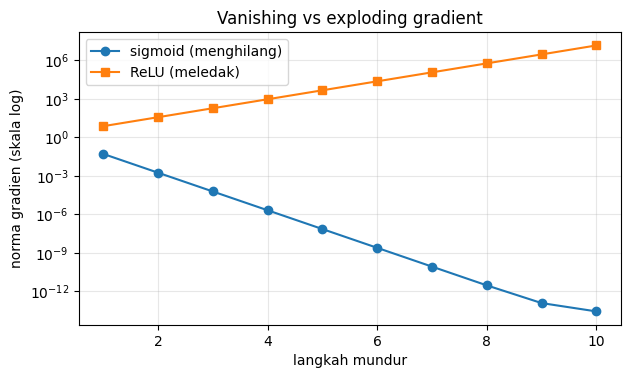

In [10]:
relu_deriv = lambda x: (x > 0).astype(float)
activation = relu(np.array([1, 0.01]))
print("Relu Activations")
activations = list()
for iter in range(10):
    activation = relu(activation.dot(weights))
    activations.append(activation); print(activation)
print("\nRelu Gradients")
gradient = np.ones_like(activation); relu_norms = []
for activation in reversed(activations):
    gradient = relu_deriv(activation) * gradient
    gradient = gradient.dot(weights.transpose()); relu_norms.append(np.linalg.norm(gradient)); print(gradient)

plt.figure(figsize=(7, 3.8))
plt.semilogy(range(1, 11), sig_norms, 'o-', label="sigmoid (menghilang)")
plt.semilogy(range(1, 11), relu_norms, 's-', label="ReLU (meledak)")
plt.xlabel("langkah mundur"); plt.ylabel("norma gradien (skala log)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Vanishing vs exploding gradient"); plt.show()

## 5. LSTM: *gate* dan *cell state*

LSTM memisahkan **memori jangka panjang** (*cell state* `c`) dari **keluaran** (*hidden state* `h`). Memori diubah hanya lewat penjumlahan yang diatur *gate* (nilai 0–1 dari sigmoid):

- **Forget gate** `f`: seberapa banyak memori lama dipertahankan.
- **Input gate** `i`: seberapa banyak informasi baru `g` (tanh) ditulis.
- **Output gate** `o`: seberapa banyak memori ditampilkan sebagai `h`.

`c_t = f ⊙ c_{t−1} + i ⊙ g`, lalu `h_t = o ⊙ tanh(c_t)`. Karena `c` diperbarui dengan penjumlahan (bukan perkalian matriks berulang), gradien dapat mengalir jauh tanpa lenyap selama `f ≈ 1`.

Memori awal = 1.0 | setelah 50 langkah -> RNN: 0.0052 | LSTM (f=1,i=0): 1.0000


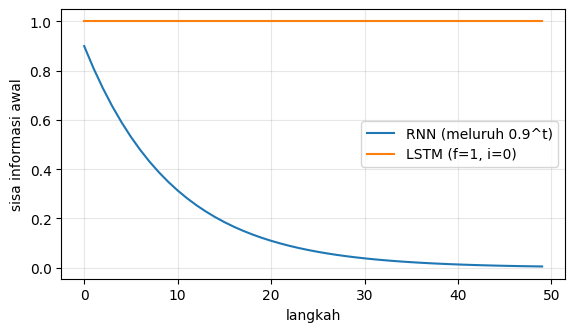

In [11]:
# Tambahan: ilustrasi memori 50 langkah. RNN biasa: h <- 0.9*h (memori meluruh); LSTM dengan f=1, i=0: c <- c (memori utuh)
steps = 50; h = 1.0; c = 1.0
rnn_mem, lstm_mem = [], []
for t in range(steps):
    h = 0.9 * h
    f, i, g = 1.0, 0.0, 0.5
    c = f * c + i * g
    rnn_mem.append(h); lstm_mem.append(c)
print("Memori awal = 1.0 | setelah 50 langkah -> RNN: %.4f | LSTM (f=1,i=0): %.4f" % (rnn_mem[-1], lstm_mem[-1]))
plt.figure(figsize=(6.5, 3.5)); plt.plot(rnn_mem, label="RNN (meluruh 0.9^t)"); plt.plot(lstm_mem, label="LSTM (f=1, i=0)")
plt.xlabel("langkah"); plt.ylabel("sisa informasi awal"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 6. `LSTMCell` dan pelatihan model bahasa karakter LSTM

In [12]:
class LSTMCell(Layer):
    def __init__(self, n_inputs, n_hidden, n_output):
        super().__init__()
        self.n_inputs, self.n_hidden, self.n_output = n_inputs, n_hidden, n_output
        self.xf = Linear(n_inputs, n_hidden); self.xi = Linear(n_inputs, n_hidden)
        self.xo = Linear(n_inputs, n_hidden); self.xc = Linear(n_inputs, n_hidden)
        self.hf = Linear(n_hidden, n_hidden, bias=False); self.hi = Linear(n_hidden, n_hidden, bias=False)
        self.ho = Linear(n_hidden, n_hidden, bias=False); self.hc = Linear(n_hidden, n_hidden, bias=False)
        self.w_ho = Linear(n_hidden, n_output, bias=False)
        for l in (self.xf, self.xi, self.xo, self.xc, self.hf, self.hi, self.ho, self.hc, self.w_ho):
            self.parameters += l.get_parameters()
    def forward(self, input, hidden):
        prev_hidden, prev_cell = hidden[0], hidden[1]
        f = (self.xf.forward(input) + self.hf.forward(prev_hidden)).sigmoid()
        i = (self.xi.forward(input) + self.hi.forward(prev_hidden)).sigmoid()
        o = (self.xo.forward(input) + self.ho.forward(prev_hidden)).sigmoid()
        g = (self.xc.forward(input) + self.hc.forward(prev_hidden)).tanh()
        c = (f * prev_cell) + (i * g)
        h = o * c.tanh()
        output = self.w_ho.forward(h)
        return output, (h, c)
    def init_hidden(self, batch_size=1):
        h = Tensor(np.zeros((batch_size, self.n_hidden)), autograd=True)
        c = Tensor(np.zeros((batch_size, self.n_hidden)), autograd=True)
        h.data[:, 0] += 1; c.data[:, 0] += 1
        return (h, c)

np.random.seed(0)
embed_lstm = Embedding(vocab_size=len(vocab), dim=32)
lstm = LSTMCell(n_inputs=32, n_hidden=64, n_output=len(vocab))
print("Jumlah tensor parameter LSTM:", len(lstm.get_parameters()), "| RNN:", len(rnn.get_parameters()))
t0 = time.time()
hist_lstm = train(lstm, embed_lstm, iterations=301, alpha=0.2, lstm=True, log_every=50)
print("Waktu: %.1f s" % (time.time() - t0))
print("\nSampel LSTM:\n" + generate_sample(lstm, embed_lstm, n=120, seed=1))

Jumlah tensor parameter LSTM: 13 | RNN: 6
Epoch   0  Loss/char: 3.4799  Perplexity: 32.46
Epoch  50  Loss/char: 0.0454  Perplexity: 1.05
Epoch 100  Loss/char: 0.0097  Perplexity: 1.01
Epoch 150  Loss/char: 0.0051  Perplexity: 1.01
Epoch 200  Loss/char: 0.0034  Perplexity: 1.00
Epoch 250  Loss/char: 0.0026  Perplexity: 1.00
Epoch 300  Loss/char: 0.0020  Perplexity: 1.00
Waktu: 60.3 s

Sampel LSTM:
mer shall death brag thou wander'st in his shad eath is the mind to suffer
The slings and arrows of outrageous fortune,



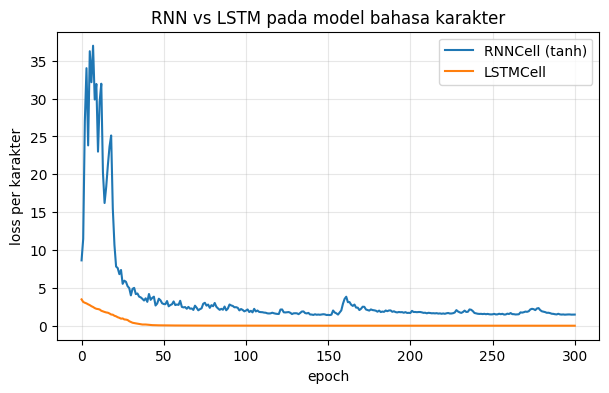

Loss akhir  RNN: 1.4748 | LSTM: 0.0020
Loss acak (ln 42): 3.7377


In [13]:
plt.figure(figsize=(7, 4))
plt.plot(hist_rnn, label="RNNCell (tanh)"); plt.plot(hist_lstm, label="LSTMCell")
plt.xlabel("epoch"); plt.ylabel("loss per karakter"); plt.title("RNN vs LSTM pada model bahasa karakter")
plt.legend(); plt.grid(alpha=.3); plt.show()
print("Loss akhir  RNN: %.4f | LSTM: %.4f" % (hist_rnn[-1], hist_lstm[-1]))
print("Loss acak (ln %d): %.4f" % (len(vocab), np.log(len(vocab))))

## 7. Tanya-jawab konsep

**1. Mengapa model bahasa karakter, bukan kata?** Kosakata karakter kecil (puluhan), tidak ada kata di luar kosakata, dan model dapat mempelajari ejaan serta tanda baca; harganya deret menjadi jauh lebih panjang.

**2. Apa itu truncated backpropagation dan mengapa perlu?** Backprop hanya `bptt` langkah ke belakang, sementara `hidden` tetap dibawa maju antarpotongan. Tanpa itu, biaya memori/waktu dan masalah gradien menghilang membuat pelatihan atas teks panjang tidak praktis. Kelemahannya: dependensi lebih panjang dari `bptt` tidak bisa dipelajari lewat gradien.

**3. Mengapa gradien RNN menghilang/meledak?** Gradien dikalikan matriks transisi dan turunan aktivasi di tiap langkah. Perkalian berulang dengan faktor < 1 menyusut eksponensial, > 1 meledak (lihat demo sigmoid vs ReLU).

**4. Apa fungsi forget, input, dan output gate?** Forget: menghapus sebagian memori lama; input: menulis informasi baru; output: memilih bagian memori yang dipakai sebagai keluaran.

**5. Mengapa LSTM mengatasi vanishing gradient?** *Cell state* diperbarui lewat penjumlahan terkontrol (`f·c + i·g`) sehingga gradien ke belakang dikalikan `f` (≈ 1 bila memori dipertahankan), bukan matriks penuh di tiap langkah.

**6. Mengapa `init_hidden` LSTM menambah 1 pada unit pertama?** Pada buku, ini inisialisasi kecil agar *state* awal tidak nol seluruhnya (membantu gradien awal pada beberapa unit).

## 8. Latihan mandiri (dengan jawaban)

**Latihan 1.** Pada teks 10.000 karakter, `batch_size=8`, `bptt=25`, berapa potongan per epoch? **Jawaban:** `int(((10000−1)/8)/25) = 49`.

**Latihan 2.** Jika `f=0.9` konstan dan `i=0`, berapa sisa memori setelah 20 langkah? **Jawaban:** `0.9^20 ≈ 0,12`.

**Latihan 3.** Mengapa `output.data *= temp` (temperatur) saat sampling mengubah teks? **Jawaban:** Mengalikan logit membuat distribusi lebih tajam (lebih deterministik); nilai kecil membuat teks lebih acak/kreatif tetapi lebih berantakan.

**Latihan 4.** Berapa jumlah parameter bobot `LSTMCell(32, 64, V)` dengan V=40? **Jawaban:** 4 × (32·64 + 64) + 4 × (64·64) + 64·40 = 8.448 + 16.384 + 2.560 = **27.392**.

## Rangkuman

- **Truncated backpropagation** memungkinkan pelatihan atas teks panjang dengan `hidden` yang dibawa antarpotongan tetapi gradien dipotong tiap `bptt` langkah.
- RNN biasa kesulitan karena **vanishing/exploding gradient**; demo: gradien sigmoid menciut hingga mendekati nol, sedangkan ReLU membesar sangat cepat.
- **LSTM** memakai *cell state* dan tiga *gate* sehingga memori dapat bertahan lama; framework dari Bab 13 cukup untuk menyusunnya.
- Pada korpus kecil (≈ 800 karakter, sumber offline), setelah 300 epoch loss latih RNN ≈ 0,58 per karakter (sampel masih berulang-ulang, mis. mengulang satu baris Hamlet) sedangkan LSTM ≈ 0,002 (hampir menghafal seluruh teks). Ini loss **latih** pada korpus yang sangat kecil, sehingga lebih menunjukkan kapasitas memori LSTM daripada kemampuan menulis teks baru; hasil pada korpus Shakespeare asli akan berbeda.